# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
# data = pandas.concat([
    # pandas.read_csv(
        # 'results/old/scores_test.csv',
    # ),
    # pandas.read_csv(
        # 'results/old/csscores_test.csv',
    # )
# ]).set_index(['problem', 'strategy'])

data = pandas.read_csv('results/small_literals.csv', index_col = ['problem', 'strategy'])

In [6]:
strategies = data.index.get_level_values('strategy').unique()
strategies

Index(['SATSolve', 'SATSolveLiteral', 'SATSolvePropagation',
       'SATSolveLiteralPropagation'],
      dtype='object', name='strategy')

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

# Analysing

In [9]:
control = ['FirstAction', 'LeanCopCut']

In [10]:
data[data.solved]

status  solved    steps  time_ms  \
problem    strategy                                                       
AGT002+2.p SATSolve                    solved    True      0.0      0.0   
           SATSolveLiteral             solved    True      0.0      0.0   
           SATSolvePropagation         solved    True      0.0      0.0   
           SATSolveLiteralPropagation  solved    True      0.0      0.0   
ALG227+1.p SATSolveLiteral             solved    True  88375.0  75848.0   
...                                       ...     ...      ...      ...   
SYN729-1.p SATSolveLiteralPropagation  solved    True    162.0     35.0   
SYN969+1.p SATSolve                    solved    True     13.0      1.0   
           SATSolveLiteral             solved    True     13.0      1.0   
           SATSolvePropagation         solved    True     13.0     44.0   
           SATSolveLiteralPropagation  solved    True     13.0      2.0   

                                                                                    info  \
problem    strategy                                                                        
AGT002+2.p SATSolve                                                        Theorem (SAT)   
           SATSolveLiteral                                                 Theorem (SAT)   
           SATSolvePropagation                                             Theorem (SAT)   
           SATSolveLiteralPropagation                                      Theorem (SAT)   
ALG227+1.p SATSolveLiteral                                      Theorem (SAT); score=1.0   
...                                                                                  ...   
SYN729-1.p SATSolveLiteralPropagation  Theorem (SAT); prop=backend:cadical-fallback,d...   
SYN969+1.p SATSolve                                                        Theorem (SAT)   
           SATSolveLiteral                                                 Theorem (SAT)   
           SATSolvePropagation         Theorem (SAT); prop=backend:cadical-fallback,d...   
           SATSolveLiteralPropagation  Theorem (SAT); prop=backend:cadical-fallback,d...   

                                      error  
problem    strategy                          
AGT002+2.p SATSolve                     NaN  
           SATSolveLiteral              NaN  
           SATSolvePropagation          NaN  
           SATSolveLiteralPropagation   NaN  
ALG227+1.p SATSolveLiteral              NaN  
...                                     ...  
SYN729-1.p SATSolveLiteralPropagation   NaN  
SYN969+1.p SATSolve                     NaN  
           SATSolveLiteral              NaN  
           SATSolvePropagation          NaN  
           SATSolveLiteralPropagation   NaN  

[760 rows x 6 columns]

In [11]:
data[data.solved].groupby(level = 1).size()

strategy
SATSolve                      151
SATSolveLiteral               220
SATSolveLiteralPropagation    193
SATSolvePropagation           196
dtype: int64

In [12]:
solved = data['solved'].unstack('strategy')

In [13]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
SATSolve                       0
SATSolveLiteral               22
SATSolveLiteralPropagation     1
SATSolvePropagation            1
dtype: int64

# Results

<Axes: xlabel='strategy'>

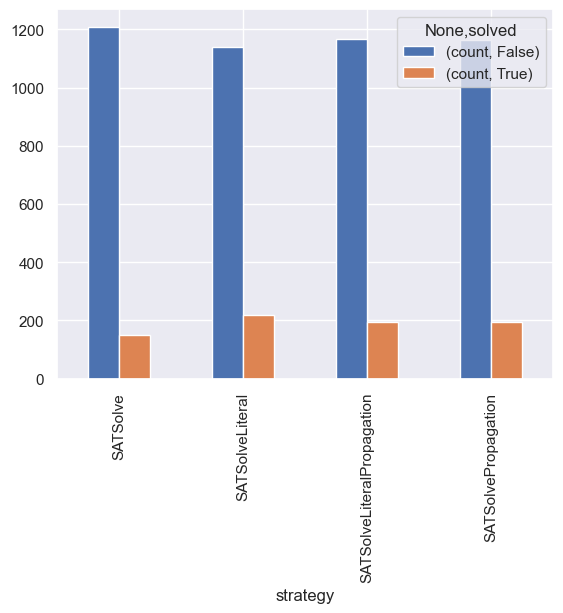

In [14]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

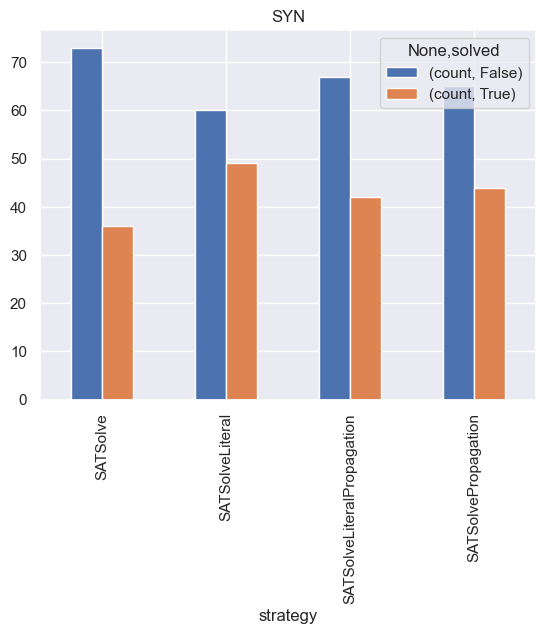

In [23]:
data[data.index.get_level_values('problem').str[:3] == 'SYN'].groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()
pyplot.title('SYN')
None

<Axes: xlabel='winner', ylabel='loser'>

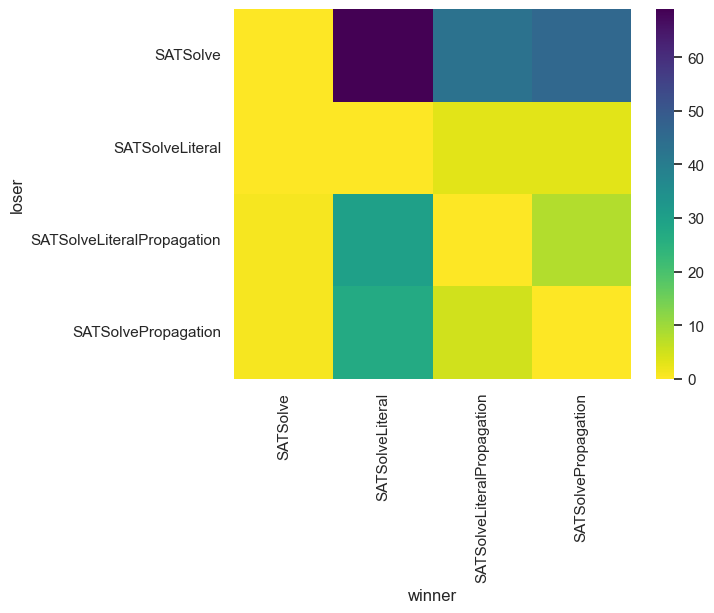

In [16]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [17]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [18]:
statistics = (
    merged
    .xs('SATSolve', level = 'strategy_right')
    # .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    # .loc[lambda x: x.index.get_level_values('strategy_left') != 'SATSolve']
    # .groupby(level = 'problem')
    # .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics.loc[lambda x: (x.steps_right == 1) & (x.steps_left > 10)].sort_values('steps_left').head(40)

,,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,length
problem,strategy_left,,,,,,,,,,,,,


# Analysis

In [19]:
diffs = data[data.index.get_level_values('strategy').isin(['SATSolve', 'SATSolveGuided'])]
diffs = diffs.groupby(level = 'problem').filter(lambda x: x.solved.any() & ~x.solved.all()).sort_index()
diffs

,,status,solved,steps,time_ms,info,error
problem,strategy,,,,,,


In [20]:
diffs.groupby(level = 'problem').filter(lambda x: x.xs(level = 'strategy', key = 'SATSolveGuided').solved)

,,status,solved,steps,time_ms,info,error
problem,strategy,,,,,,
